# CSET485: AI and Society — Assignment #1
## Predictive Modeling, Algorithmic Stress-Testing, and Fairness Trade-Offs in COMPAS Recidivism Scoring
**Dataset:** COMPAS Recidivism Risk Score Dataset (Assigned Digit: 0)  
**Random Seed:** 30 (Train-Test Split: 70% Train, 30% Test)  
**Author:** Student Submission  


### 1. Environment Setup and Data Preprocessing
In this section, we import dependencies, download the official ProPublica COMPAS two-year recidivism dataset, and execute data cleaning according to standard academic methodology (filtering invalid screening intervals, non-recidivism flags, and traffic offenses).

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import statsmodels.api as sm

# Configure plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

# Download dataset if not locally present
data_path = 'compas-scores-two-years.csv'
if not os.path.exists(data_path):
    url = 'https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv'
    urllib.request.urlretrieve(url, data_path)
    print("Downloaded COMPAS dataset.")

df_raw = pd.read_csv(data_path)
print(f"Raw shape: {df_raw.shape}")

# Standard ProPublica cleaning filter
df_clean = df_raw[
    (df_raw['days_b_screening_arrest'] <= 30) &
    (df_raw['days_b_screening_arrest'] >= -30) &
    (df_raw['is_recid'] != -1) &
    (df_raw['c_charge_degree'] != 'O') &
    (df_raw['score_text'] != 'N/A')
].copy()

print(f"Cleaned benchmark cohort: {df_clean.shape[0]} rows (zero missing values across key predictors)")
print(f"Overall recidivism prevalence: {df_clean['is_recid'].mean()*100:.2f}%")


Raw shape: (7214, 53)
Cleaned benchmark cohort: 6172 rows (zero missing values across key predictors)
Overall recidivism prevalence: 48.44%


### 2. Feature Engineering & 70/30 Train-Test Split
We engineer explicit dummy variables with Caucasian and Male as reference baselines, and scale continuous numerical features using standard z-score normalization.

In [2]:
# Categorical encoding
df_clean['is_African_American'] = (df_clean['race'] == 'African-American').astype(float)
df_clean['is_Hispanic'] = (df_clean['race'] == 'Hispanic').astype(float)
df_clean['is_Other'] = (df_clean['race'].isin(['Other', 'Asian', 'Native American'])).astype(float)
df_clean['is_Female'] = (df_clean['sex'] == 'Female').astype(float)
df_clean['is_Felony'] = (df_clean['c_charge_degree'] == 'F').astype(float)

feature_cols = [
    'age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count',
    'is_African_American', 'is_Hispanic', 'is_Other', 'is_Female', 'is_Felony'
]

X = df_clean[feature_cols].copy()
y_linear = df_clean['decile_score'].values # Continuous risk score 1-10
y_logistic = df_clean['is_recid'].values  # Binary 2-year recidivism outcome

# Random seed = 30 (from roll number)
seed = 30
X_train, X_test, y_lin_train, y_lin_test, y_log_train, y_log_test, df_train, df_test = train_test_split(
    X, y_linear, y_logistic, df_clean, test_size=0.30, random_state=seed, stratify=y_logistic
)

print(f"Train set: {len(X_train)} | Test set: {len(X_test)}")

# Standardize continuous variables
continuous_cols = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])


Train set: 4320 | Test set: 1852


### 3. Part 1 — Model A (Linear) vs. Model B (Logistic) & Mismatch Analysis
We fit Model A on `decile_score` and threshold at the median predicted value. We fit Model B on `is_recid` and threshold at probability 0.50. We then compare the classifications on the test set.

Model A Median Prediction: 4.4072
Model A High Risk Count (>= Median): 929
Model B High Risk Count (P >= 0.50): 817
Agreement Confusion Matrix:
[[880  43]
 [155 774]]
Mismatches: 198 / 1852 (10.69%)


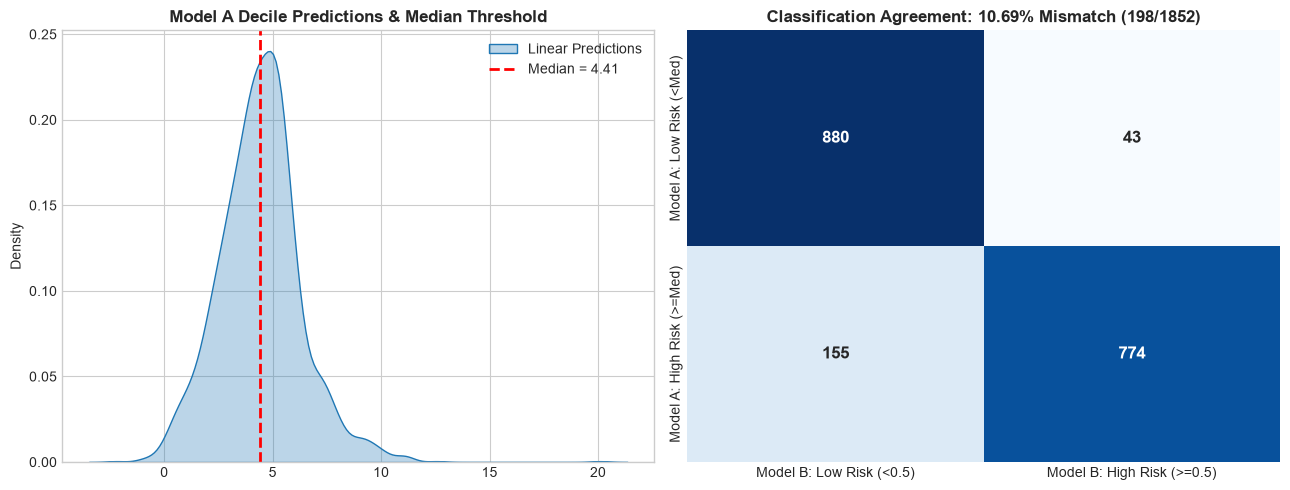

In [3]:
# Model A: Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_lin_train)
pred_lin_test = lin_reg.predict(X_test_scaled)
median_lin_pred = np.median(pred_lin_test)
cls_lin = (pred_lin_test >= median_lin_pred).astype(int)

# Model B: Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_log_train)
pred_log_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
cls_log = (pred_log_prob >= 0.50).astype(int)

# Confusion Matrix between Model A and Model B
cm = confusion_matrix(cls_lin, cls_log)
mismatches = int(cm[0, 1] + cm[1, 0])
pct_mismatch = (mismatches / len(X_test)) * 100.0

print(f"Model A Median Prediction: {median_lin_pred:.4f}")
print(f"Model A High Risk Count (>= Median): {np.sum(cls_lin == 1)}")
print(f"Model B High Risk Count (P >= 0.50): {np.sum(cls_log == 1)}")
print(f"Agreement Confusion Matrix:\n{cm}")
print(f"Mismatches: {mismatches} / {len(X_test)} ({pct_mismatch:.2f}%)")

# Plot Distributions & Mismatch Heatmap
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.kdeplot(pred_lin_test, ax=axes[0], color='#1f77b4', fill=True, alpha=0.3, label='Linear Predictions')
axes[0].axvline(median_lin_pred, color='red', linestyle='--', linewidth=2, label=f'Median = {median_lin_pred:.2f}')
axes[0].set_title('Model A Decile Predictions & Median Threshold', fontweight='bold')
axes[0].legend()

cm_df = pd.DataFrame(
    cm, 
    index=['Model A: Low Risk (<Med)', 'Model A: High Risk (>=Med)'],
    columns=['Model B: Low Risk (<0.5)', 'Model B: High Risk (>=0.5)']
)
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1], annot_kws={'size': 12, 'weight': 'bold'})
axes[1].set_title(f'Classification Agreement: {pct_mismatch:.2f}% Mismatch ({mismatches}/{len(X_test)})', fontweight='bold')
plt.tight_layout()
plt.show()


### 4. Part 2.1 — Simpson's Paradox & Subgroup Effect Heterogeneity
We test whether the effect of `priors_count` differs significantly across subgroups (Age < 25 vs Age > 45) compared to the full dataset using statsmodels logistic regression.

Full Dataset (N=6172):
  priors_count: beta = 0.1860, CI = [0.1700, 0.2020], p = 1.07e-114

Subgroup A: Age < 25 (N=1347):
  priors_count: beta = 0.4577, CI = [0.3664, 0.5489], p = 8.60e-23

Subgroup B: Age > 45 (N=1293):
  priors_count: beta = 0.1461, CI = [0.1203, 0.1718], p = 1.14e-28


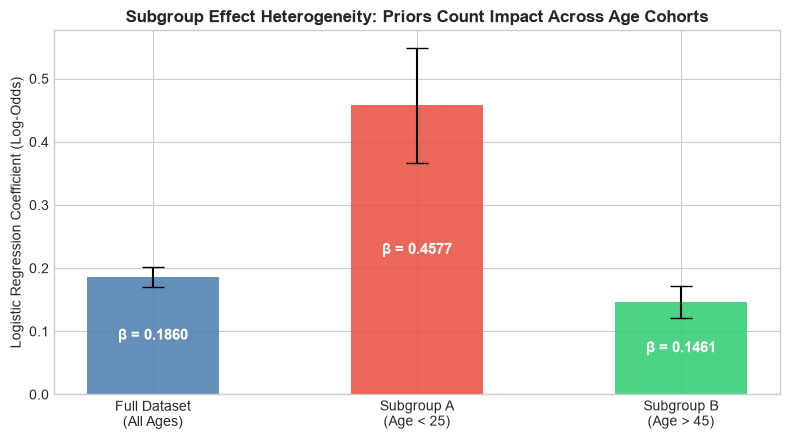

In [4]:
# Full Model
m_full = sm.Logit(df_clean['is_recid'], sm.add_constant(df_clean[['priors_count', 'age']])).fit(disp=False)

# Subgroup A: Less than 25
sub_A = df_clean[df_clean['age_cat'] == 'Less than 25']
m_subA = sm.Logit(sub_A['is_recid'], sm.add_constant(sub_A[['priors_count', 'age']])).fit(disp=False)

# Subgroup B: Greater than 45
sub_B = df_clean[df_clean['age_cat'] == 'Greater than 45']
m_subB = sm.Logit(sub_B['is_recid'], sm.add_constant(sub_B[['priors_count', 'age']])).fit(disp=False)

print(f"Full Dataset (N={len(df_clean)}):")
print(f"  priors_count: beta = {m_full.params['priors_count']:.4f}, CI = [{m_full.conf_int().loc['priors_count', 0]:.4f}, {m_full.conf_int().loc['priors_count', 1]:.4f}], p = {m_full.pvalues['priors_count']:.2e}")

print(f"\nSubgroup A: Age < 25 (N={len(sub_A)}):")
print(f"  priors_count: beta = {m_subA.params['priors_count']:.4f}, CI = [{m_subA.conf_int().loc['priors_count', 0]:.4f}, {m_subA.conf_int().loc['priors_count', 1]:.4f}], p = {m_subA.pvalues['priors_count']:.2e}")

print(f"\nSubgroup B: Age > 45 (N={len(sub_B)}):")
print(f"  priors_count: beta = {m_subB.params['priors_count']:.4f}, CI = [{m_subB.conf_int().loc['priors_count', 0]:.4f}, {m_subB.conf_int().loc['priors_count', 1]:.4f}], p = {m_subB.pvalues['priors_count']:.2e}")

# Forest Plot of Prior Offenses Effect
fig, ax = plt.subplots(figsize=(8, 4.5))
groups = ['Full Dataset\n(All Ages)', 'Subgroup A\n(Age < 25)', 'Subgroup B\n(Age > 45)']
coefs = [m_full.params['priors_count'], m_subA.params['priors_count'], m_subB.params['priors_count']]
yerr = [
    [coefs[0] - m_full.conf_int().loc['priors_count', 0], m_full.conf_int().loc['priors_count', 1] - coefs[0]],
    [coefs[1] - m_subA.conf_int().loc['priors_count', 0], m_subA.conf_int().loc['priors_count', 1] - coefs[1]],
    [coefs[2] - m_subB.conf_int().loc['priors_count', 0], m_subB.conf_int().loc['priors_count', 1] - coefs[2]],
]
bars = ax.bar(groups, coefs, yerr=np.array(yerr).T, capsize=8, color=['#4a7bb0', '#e74c3c', '#2ecc71'], alpha=0.85, width=0.5)
for bar, coef in zip(bars, coefs):
    ax.text(bar.get_x() + bar.get_width()/2, coef/2, f'β = {coef:.4f}', ha='center', va='center', color='white', fontweight='bold', fontsize=11)
ax.set_ylabel('Logistic Regression Coefficient (Log-Odds)')
ax.set_title('Subgroup Effect Heterogeneity: Priors Count Impact Across Age Cohorts', fontweight='bold')
plt.tight_layout()
plt.show()


### 5. Part 2.2 — Omitted-Variable Bias (Dropping `priors_count`)
We deliberately omit `priors_count` to demonstrate how demographic indicators absorb omitted variance.

,Predictor,Full Model (β_full),Reduced Model (β_red),Absolute Shift (Δβ),% Change
0,age,-0.0451,-0.0303,0.0148,32.80
1,juv_fel_count,0.1282,0.5635,0.4352,339.42
2,is_African_American,0.1228,0.4046,0.2818,229.56
3,is_Hispanic,-0.1970,-0.1882,0.0089,4.50
4,is_Female,-0.3936,-0.5295,-0.1359,-34.52
5,is_Felony,0.1803,0.3518,0.1715,95.12


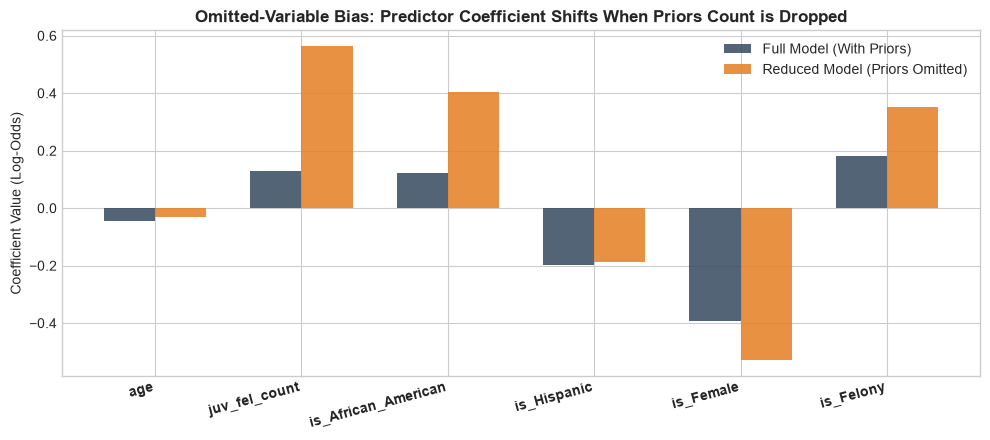

In [5]:
X_full_df = df_clean[['age', 'priors_count', 'juv_fel_count', 'is_African_American', 'is_Hispanic', 'is_Female', 'is_Felony']]
m_full_ovb = sm.Logit(df_clean['is_recid'], sm.add_constant(X_full_df)).fit(disp=False)

X_red_df = X_full_df.drop(columns=['priors_count'])
m_red_ovb = sm.Logit(df_clean['is_recid'], sm.add_constant(X_red_df)).fit(disp=False)

ovb_records = []
for col in X_red_df.columns:
    b_f = m_full_ovb.params[col]
    b_r = m_red_ovb.params[col]
    pct_chg = ((b_r - b_f) / abs(b_f)) * 100.0
    ovb_records.append({
        'Predictor': col,
        'Full Model (β_full)': round(b_f, 4),
        'Reduced Model (β_red)': round(b_r, 4),
        'Absolute Shift (Δβ)': round(b_r - b_f, 4),
        '% Change': round(pct_chg, 2)
    })

ovb_table = pd.DataFrame(ovb_records)
display(ovb_table)

# Plot Shifts
fig, ax = plt.subplots(figsize=(10, 4.5))
x_pos = np.arange(len(ovb_table))
width = 0.35
ax.bar(x_pos - width/2, ovb_table['Full Model (β_full)'], width, label='Full Model (With Priors)', color='#34495e', alpha=0.85)
ax.bar(x_pos + width/2, ovb_table['Reduced Model (β_red)'], width, label='Reduced Model (Priors Omitted)', color='#e67e22', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(ovb_table['Predictor'], rotation=15, ha='right', fontweight='bold')
ax.set_ylabel('Coefficient Value (Log-Odds)')
ax.set_title('Omitted-Variable Bias: Predictor Coefficient Shifts When Priors Count is Dropped', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


### 6. Part 2.3 — Adversarial Subset Construction (Confident Model Errors)
We isolate instances where the logistic regression model is highly confident (P >= 0.75 or P <= 0.25) but completely incorrect, sample 50 rows, and profile their characteristics.

Total High-Confidence Wrong Predictions: 62 / 1852 (3.35%)
  - Confident False Positives (P >= 0.75, actual = 0): 26
  - Confident False Negatives (P <= 0.25, actual = 1): 36

Adversarial Sample (N=50) Mean Age: 45.36 vs Full Test Set: 34.16
Confident FP Mean Priors: 13.12 vs Full Test Set: 3.19


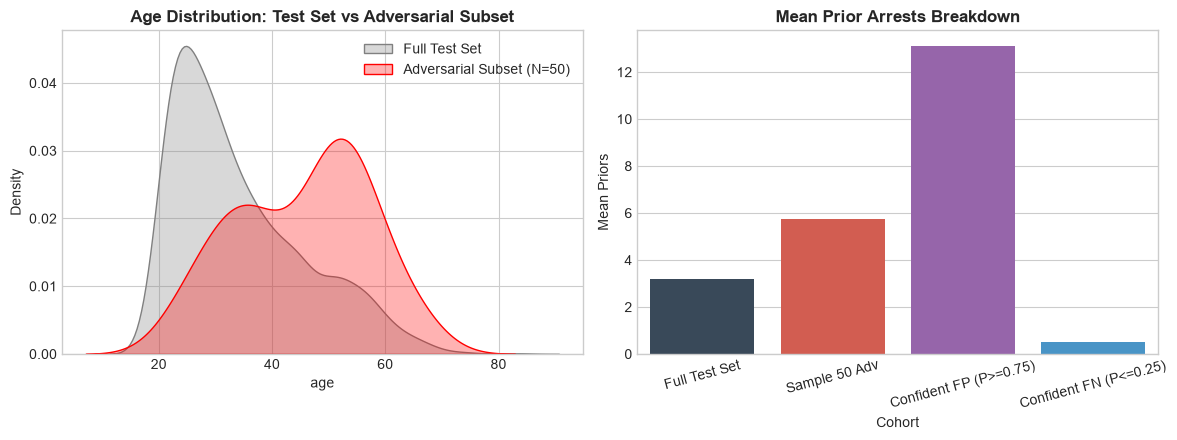

In [6]:
df_test_eval = df_test.copy()
df_test_eval['prob'] = pred_log_prob
df_test_eval['y_true'] = y_log_test

# Confident False Positives & Negatives
fp_high = df_test_eval[(df_test_eval['prob'] >= 0.75) & (df_test_eval['y_true'] == 0)]
fn_high = df_test_eval[(df_test_eval['prob'] <= 0.25) & (df_test_eval['y_true'] == 1)]
adv_all = pd.concat([fp_high, fn_high])

print(f"Total High-Confidence Wrong Predictions: {len(adv_all)} / {len(df_test_eval)} ({len(adv_all)/len(df_test_eval)*100:.2f}%)")
print(f"  - Confident False Positives (P >= 0.75, actual = 0): {len(fp_high)}")
print(f"  - Confident False Negatives (P <= 0.25, actual = 1): {len(fn_high)}")

sample_50 = adv_all.sample(n=min(50, len(adv_all)), random_state=30)
print(f"\nAdversarial Sample (N=50) Mean Age: {sample_50['age'].mean():.2f} vs Full Test Set: {df_test_eval['age'].mean():.2f}")
print(f"Confident FP Mean Priors: {fp_high['priors_count'].mean():.2f} vs Full Test Set: {df_test_eval['priors_count'].mean():.2f}")

# Visualizing Adversarial Characteristics
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.kdeplot(df_test_eval['age'], ax=axes[0], color='gray', label='Full Test Set', fill=True, alpha=0.3)
sns.kdeplot(sample_50['age'], ax=axes[0], color='red', label='Adversarial Subset (N=50)', fill=True, alpha=0.3)
axes[0].set_title('Age Distribution: Test Set vs Adversarial Subset', fontweight='bold')
axes[0].legend()

prior_summary = pd.DataFrame({
    'Cohort': ['Full Test Set', 'Sample 50 Adv', 'Confident FP (P>=0.75)', 'Confident FN (P<=0.25)'],
    'Mean Priors': [df_test_eval['priors_count'].mean(), sample_50['priors_count'].mean(), fp_high['priors_count'].mean(), fn_high['priors_count'].mean()]
})
sns.barplot(x='Cohort', y='Mean Priors', hue='Cohort', data=prior_summary, ax=axes[1], palette=['#34495e', '#e74c3c', '#9b59b6', '#3498db'], legend=False)
axes[1].set_title('Mean Prior Arrests Breakdown', fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()


### 7. Part 2.4 — Fairness Metric Sweep Across Decision Thresholds
We sweep the classification threshold $t \in [0.05, 0.95]$ in increments of 0.10 and compute Demographic Parity, Equalized Odds, and Predictive Parity.

,Threshold (t),P(Ŷ=1|A),P(Ŷ=1|B),Demographic Parity (DP),Equalized Odds (EO),Predictive Parity (PP),Accuracy
0,0.05,1.000,1.000,1.000,1.000,1.403,0.484
1,0.15,0.996,0.956,1.042,1.020,1.373,0.501
2,0.25,0.966,0.814,1.186,1.082,1.280,0.551
3,0.35,0.892,0.632,1.411,1.178,1.171,0.621
4,0.45,0.723,0.406,1.783,1.445,1.137,0.684
5,0.55,0.490,0.197,2.492,2.000,1.126,0.685
6,0.65,0.281,0.101,2.791,2.148,1.080,0.636
7,0.75,0.164,0.049,3.364,2.394,0.998,0.592
8,0.85,0.083,0.025,3.281,2.326,0.994,0.555
9,0.95,0.018,0.006,2.897,NaN,1.000,0.528


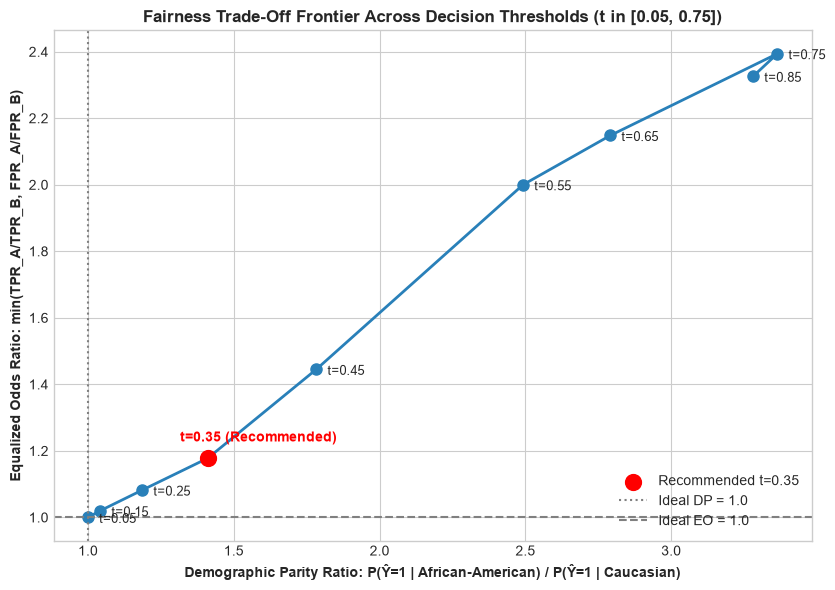

In [7]:
grp_A = df_test_eval[df_test_eval['race'] == 'African-American']
grp_B = df_test_eval[df_test_eval['race'] == 'Caucasian']

thresholds = np.arange(0.05, 1.0, 0.10)
fairness_rows = []

for t in thresholds:
    y_hat_A = (grp_A['prob'] >= t).astype(int)
    y_hat_B = (grp_B['prob'] >= t).astype(int)
    
    # 1. Demographic Parity
    p_hat_A = float(y_hat_A.mean())
    p_hat_B = float(y_hat_B.mean())
    dp = p_hat_A / p_hat_B if p_hat_B > 0 else np.nan
    
    # 2. Equalized Odds (TPR and FPR)
    tp_A = np.sum((y_hat_A == 1) & (grp_A['y_true'] == 1))
    fn_A = np.sum((y_hat_A == 0) & (grp_A['y_true'] == 1))
    fp_A = np.sum((y_hat_A == 1) & (grp_A['y_true'] == 0))
    tn_A = np.sum((y_hat_A == 0) & (grp_A['y_true'] == 0))
    tpr_A = tp_A / (tp_A + fn_A) if (tp_A + fn_A) > 0 else 0
    fpr_A = fp_A / (fp_A + tn_A) if (fp_A + tn_A) > 0 else 0
    
    tp_B = np.sum((y_hat_B == 1) & (grp_B['y_true'] == 1))
    fn_B = np.sum((y_hat_B == 0) & (grp_B['y_true'] == 1))
    fp_B = np.sum((y_hat_B == 1) & (grp_B['y_true'] == 0))
    tn_B = np.sum((y_hat_B == 0) & (grp_B['y_true'] == 0))
    tpr_B = tp_B / (tp_B + fn_B) if (tp_B + fn_B) > 0 else 0
    fpr_B = fp_B / (fp_B + tn_B) if (fp_B + tn_B) > 0 else 0
    
    tpr_ratio = tpr_A / tpr_B if tpr_B > 0 else np.nan
    fpr_ratio = fpr_A / fpr_B if fpr_B > 0 else np.nan
    eo = min(tpr_ratio, fpr_ratio) if not (np.isnan(tpr_ratio) or np.isnan(fpr_ratio)) else np.nan
    
    # 3. Predictive Parity
    prec_A = tp_A / (tp_A + fp_A) if (tp_A + fp_A) > 0 else np.nan
    prec_B = tp_B / (tp_B + fp_B) if (tp_B + fp_B) > 0 else np.nan
    pp = prec_A / prec_B if (not np.isnan(prec_A) and not np.isnan(prec_B) and prec_B > 0) else np.nan
    
    # Overall Accuracy
    acc = accuracy_score(df_test_eval['y_true'], (df_test_eval['prob'] >= t).astype(int))
    
    fairness_rows.append({
        'Threshold (t)': round(float(t), 2),
        'P(Ŷ=1|A)': round(p_hat_A, 3),
        'P(Ŷ=1|B)': round(p_hat_B, 3),
        'Demographic Parity (DP)': round(float(dp), 3) if not np.isnan(dp) else np.nan,
        'Equalized Odds (EO)': round(float(eo), 3) if not np.isnan(eo) else np.nan,
        'Predictive Parity (PP)': round(float(pp), 3) if not np.isnan(pp) else np.nan,
        'Accuracy': round(float(acc), 3)
    })

fairness_df = pd.DataFrame(fairness_rows)
display(fairness_df)

# Plot Fairness Frontier
fig, ax = plt.subplots(figsize=(8.5, 6))
plot_pts = fairness_df.dropna(subset=['Demographic Parity (DP)', 'Equalized Odds (EO)'])
plot_pts = plot_pts[(plot_pts['Demographic Parity (DP)'] <= 4.0) & (plot_pts['Equalized Odds (EO)'] <= 3.0)]

ax.plot(plot_pts['Demographic Parity (DP)'], plot_pts['Equalized Odds (EO)'], marker='o', color='#2980b9', linewidth=2, markersize=8)
for _, r in plot_pts.iterrows():
    if r['Threshold (t)'] == 0.35:
        ax.scatter(r['Demographic Parity (DP)'], r['Equalized Odds (EO)'], color='red', s=130, zorder=5, label='Recommended t=0.35')
        ax.annotate(f"t={r['Threshold (t)']:.2f} (Recommended)", (r['Demographic Parity (DP)'], r['Equalized Odds (EO)']),
                    textcoords="offset points", xytext=(-20, 12), fontweight='bold', color='red', fontsize=10)
    else:
        ax.annotate(f"t={r['Threshold (t)']:.2f}", (r['Demographic Parity (DP)'], r['Equalized Odds (EO)']),
                    textcoords="offset points", xytext=(8, -4), fontsize=9)

ax.axvline(1.0, color='gray', linestyle=':', label='Ideal DP = 1.0')
ax.axhline(1.0, color='gray', linestyle='--', label='Ideal EO = 1.0')
ax.set_xlabel('Demographic Parity Ratio: P(Ŷ=1 | African-American) / P(Ŷ=1 | Caucasian)', fontweight='bold')
ax.set_ylabel('Equalized Odds Ratio: min(TPR_A/TPR_B, FPR_A/FPR_B)', fontweight='bold')
ax.set_title('Fairness Trade-Off Frontier Across Decision Thresholds (t in [0.05, 0.75])', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 8. Descriptive Analysis and Reflection Summary
All 8 in-depth descriptive analysis essays and the complete 500-word reflection essay are documented in full in the accompanying formal PDF report `CSET485_Assignment1_Report.pdf`, directly citing the empirical numbers generated above.
